# Forzy — Detecção de Anomalias em Motor Industrial
## LSTM Forecaster 1-step (self-supervised)

**Challenge FIAP / Forzy-Promon — módulo de Modelagem**

---

### O problema

Os dados de sensores **não possuem rótulo de saída**. Não existe coluna `falha`,
`anomalia` ou `status de atenção`. Não há nenhum evento de falha documentado no
histórico coletado.

Logo, classificação supervisionada é inviável. O pedido da empresa também não
pede isso — pede *base-line de operação* e *alerta de desvio do esperado*, que é
um problema **não-supervisionado**.

### A solução

Um modelo que **prevê o próximo instante** em vez de classificar.

| | |
|---|---|
| Entrada | janela de 30 s × `[velocidade, aceleracao, temperatura]` |
| Saída | as 3 grandezas no instante seguinte (t+1s) |
| Rótulo | o próprio valor seguinte, já presente no dado (**self-supervised**) |
| Treino | apenas operação normal (`estado == ON`) |
| Score de anomalia | resíduo \|real − previsto\| normalizado |
| Alarme | resíduo acima do percentil 99 da validação |

O modelo aprende como o motor saudável se comporta. Quando a realidade diverge da
previsão, o erro cresce — e o erro é o alarme. **Nenhuma falha precisa ter sido
observada no treino.**

### Entregas do pedido da empresa cobertas

- ✅ *"modelo de ML para estabelecer o base-line de operação"* → o modelo treinado **é** o baseline
- ✅ *"modelo que preveja anomalias para gerar alertas"* → o resíduo
- ⬜ *"prever o momento de parada para manutenção"* → exige extrapolação de tendência + dado do fabricante (fora deste escopo)

## 0. Configuração

In [1]:
import json, math, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

# ---------------------------------------------------------------- reprodutibilidade
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# ---------------------------------------------------------------- hiperparâmetros
CFG = {
    # dados -----------------------------------------------------------------
    "grade_s":      1,      # passo da grade temporal (igual à Silver)
    "limiar_off":   0.1,    # velocidade abaixo disso = motor parado (igual à Silver)
    "gap_sessao_s": 30,     # gap maior que isso abre nova sessão
    "ffill_limite": 30,     # nº máx. de passos preenchidos por forward-fill

    # janelamento -----------------------------------------------------------
    "janela":       30,     # timesteps de entrada (30 s)
    "horizonte":    1,      # passos à frente previstos (1 s)
    "purge":        30,     # gap entre splits, evita vazamento por sobreposição

    # split -----------------------------------------------------------------
    "chunk":        200,    # tamanho do pedaço sorteado para treino/val/teste
    "padrao_split": ["treino"] * 5 + ["val"] + ["teste"],   # rodízio dos chunks

    # modelo ----------------------------------------------------------------
    "hidden":       32,
    "camadas":      1,
    "dropout":      0.2,
    "lr":           1e-3,
    "batch":        64,
    "epocas_max":   200,
    "paciencia":    20,     # early stopping

    # detecção --------------------------------------------------------------
    "percentil_thr": 99.0,
}

FEATURES = ["velocidade", "aceleracao", "temperatura"]
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | device: {DEVICE}")

torch 2.12.0+cpu | device: cpu


## 1. Carga dos dados

Lê a camada **Silver** do Data Lake se estiver disponível localmente; caso
contrário cai para o CSV bruto e replica as transformações da Silver aqui mesmo
(mesma lógica de `lambda_silver.py`), para o notebook rodar sem credencial AWS.

In [2]:
RAIZ = Path.cwd()
while not (RAIZ / "dataset-forzy.csv").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent

CAMINHO_SILVER = RAIZ / "silver"
CAMINHO_CSV    = RAIZ / "dataset-forzy.csv"
ASSET_TAG      = "MOTOR-01"


def carregar_silver(caminho: Path) -> pd.DataFrame | None:
    """Lê o Parquet particionado da Silver, se existir."""
    if not caminho.exists():
        return None
    arquivos = list(caminho.rglob("*.parquet"))
    if not arquivos:
        return None
    df = pd.concat([pd.read_parquet(a) for a in arquivos], ignore_index=True)
    print(f"[Silver] {len(arquivos)} arquivo(s), {len(df)} linhas")
    return df


def carregar_csv(caminho: Path) -> pd.DataFrame:
    """Lê o CSV bruto do IO-Link Master e converte de wide para long."""
    colunas = ["ts", "raw_p1", "raw_p2",
               "v1_velocidade", "v1_aceleracao", "v1_temperatura",
               "v2_velocidade", "v2_aceleracao", "v2_temperatura"]
    bruto = pd.read_csv(caminho, sep=";", skiprows=3, header=None,
                        names=colunas, decimal=".")
    bruto["ts"] = pd.to_datetime(bruto["ts"])

    partes = []
    for porta, pref in ((1, "v1_"), (2, "v2_")):
        p = bruto[["ts", pref + "velocidade", pref + "aceleracao", pref + "temperatura"]].copy()
        p.columns = ["event_time"] + FEATURES
        p["port"] = porta
        partes.append(p)

    df = pd.concat(partes, ignore_index=True)
    df["asset_tag"] = ASSET_TAG
    df = df.dropna(subset=FEATURES, how="all")
    print(f"[CSV] {len(bruto)} linhas brutas -> {len(df)} linhas long (2 portas)")
    return df


df = carregar_silver(CAMINHO_SILVER)
ORIGEM = "silver"
if df is None:
    df = carregar_csv(CAMINHO_CSV)
    ORIGEM = "csv"

# a TAG real vem do dado; o valor acima é só o padrão de quando se lê o CSV cru
if "asset_tag" in df.columns:
    ASSET_TAG = str(df["asset_tag"].iloc[0])

print(f"origem: {ORIGEM} | asset_tag: {ASSET_TAG}")
print(f"período: {df.event_time.min()} -> {df.event_time.max()}")
df.head()

[Silver] 1 arquivo(s), 20152 linhas
origem: silver | asset_tag: MOTOR-220V-01
período: 2026-05-19 11:46:10 -> 2026-05-19 15:43:14


,asset_tag,port,event_time,sessao_id,velocidade,aceleracao,temperatura,estado,interpolado,flags
0,MOTOR-220V-01,1,2026-05-19 11:46:10,1,0.04,0.0,27.0,OFF,False,
1,MOTOR-220V-01,1,2026-05-19 11:46:11,1,0.04,0.0,27.0,OFF,False,
2,MOTOR-220V-01,1,2026-05-19 11:46:12,1,0.04,0.0,27.0,OFF,True,
3,MOTOR-220V-01,1,2026-05-19 11:46:13,1,0.04,0.0,27.0,OFF,True,
4,MOTOR-220V-01,1,2026-05-19 11:46:14,1,0.04,0.0,27.0,OFF,False,


## 2. Grade temporal, sessões e estado ON/OFF

Três problemas do dado bruto que quebram uma LSTM se não forem tratados:

1. **Amostragem irregular** — Δt tem mediana 0,59 s mas média 1,98 s e máximo de
   228 s. LSTM assume passo fixo. Solução: reamostrar em grade de 1 s.
2. **Duplicatas** — 69 % das linhas repetem os mesmos valores de sensor.
   Resolvido pela agregação da reamostragem.
3. **Gaps longos** — 21 intervalos acima de 60 s. Não podem ser interpolados como
   se fossem contínuos; abrem nova **sessão**.

O rótulo **ON/OFF existe e é derivável** — não precisa de anotação manual. A
velocidade é bimodal (parado ≈ 0,04 / rodando ≈ 6,4–7,5), então um limiar em 0,1
separa os regimes de forma determinística.

In [3]:
def preparar(df: pd.DataFrame, cfg: dict) -> pd.DataFrame:
    """Grade fixa por porta, marcação de sessão, estado ON/OFF e flag de interpolado."""
    if ORIGEM == "silver":               # a Silver já entrega tudo pronto
        return df.sort_values(["port", "event_time"]).reset_index(drop=True)

    saida = []
    for porta, g in df.groupby("port"):
        g = g.set_index("event_time").sort_index()

        # ---- sessões: gap grande interrompe a continuidade física do sinal
        dt = g.index.to_series().diff().dt.total_seconds()
        sessao = (dt > cfg["gap_sessao_s"]).cumsum() + 1
        g["sessao_id"] = sessao.values

        # ---- grade fixa dentro de cada sessão
        for sid, gs in g.groupby("sessao_id"):
            r = gs[FEATURES].resample(f"{cfg['grade_s']}s").mean()
            r["interpolado"] = r["velocidade"].isna()          # balde vazio = preenchido
            r = r.ffill(limit=cfg["ffill_limite"]).dropna(subset=FEATURES)
            r["sessao_id"] = sid
            r["port"] = porta
            r["asset_tag"] = ASSET_TAG
            saida.append(r.reset_index())

    out = pd.concat(saida, ignore_index=True)
    out["estado"] = np.where(out["velocidade"] < CFG["limiar_off"], "OFF", "ON")
    return out.sort_values(["port", "event_time"]).reset_index(drop=True)


dados = preparar(df, CFG)

resumo = (dados.groupby(["port", "estado"]).size().unstack(fill_value=0)
          .assign(total=lambda d: d.sum(axis=1)))
resumo["%_ON"] = (100 * resumo["ON"] / resumo["total"]).round(1)
print(resumo)
print(f"\ninterpolado: {100 * dados.interpolado.mean():.1f}% das linhas")

estado   OFF    ON  total  %_ON
port                           
1       7787  2289  10076  22.7
2       7790  2286  10076  22.7

interpolado: 55.4% das linhas


### 2.1 Confirmação da bimodalidade

Verificação visual de que o limiar `velocidade = 0.1` separa mesmo os dois
regimes, em vez de cortar no meio de uma distribuição contínua.

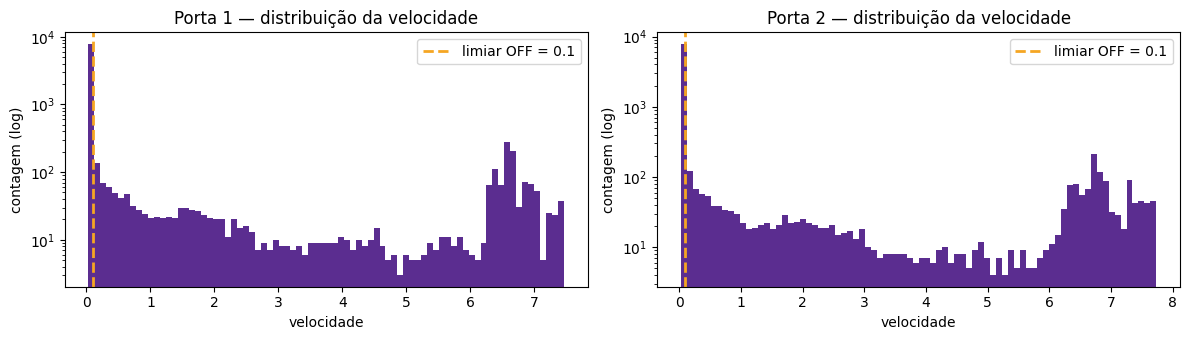

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, porta in zip(axs, sorted(dados.port.unique())):
    v = dados.loc[dados.port == porta, "velocidade"]
    ax.hist(v, bins=80, color="#5b2d90")
    ax.axvline(CFG["limiar_off"], color="#f5a623", ls="--", lw=2,
               label=f"limiar OFF = {CFG['limiar_off']}")
    ax.set_yscale("log")
    ax.set_title(f"Porta {porta} — distribuição da velocidade")
    ax.set_xlabel("velocidade"); ax.set_ylabel("contagem (log)")
    ax.legend()
plt.tight_layout(); plt.show()

## 3. Blocos de operação

Uma **janela nunca pode atravessar** uma borda ON→OFF nem uma troca de sessão.
Se atravessar, o modelo aprende a descontinuidade artificial em vez da dinâmica
do motor.

Bloco = trecho contínuo de `estado == ON`, dentro de uma mesma sessão e porta.

In [5]:
def blocos_on(dados: pd.DataFrame) -> list[pd.DataFrame]:
    """Trechos contínuos de operação (ON), sem atravessar sessão ou porta."""
    out = []
    for (porta, sid), g in dados.groupby(["port", "sessao_id"]):
        g = g.sort_values("event_time").reset_index(drop=True)
        on = g["estado"] == "ON"
        grupo = (on != on.shift()).cumsum()
        for _, blk in g[on].groupby(grupo[on]):
            if len(blk) >= CFG["janela"] + CFG["horizonte"]:
                out.append(blk.reset_index(drop=True))
    return out


BLOCOS = blocos_on(dados)

linhas = [{
    "bloco": i, "porta": int(b.port.iloc[0]), "duração_s": len(b),
    "início": b.event_time.iloc[0].time(), "fim": b.event_time.iloc[-1].time(),
    "temp_min": b.temperatura.min(), "temp_max": b.temperatura.max(),
    "interp_%": round(100 * b.interpolado.mean(), 1),
} for i, b in enumerate(BLOCOS)]

tabela = pd.DataFrame(linhas)
print(tabela.to_string(index=False))
print(f"\n{len(BLOCOS)} blocos | {sum(len(b) for b in BLOCOS)} segundos de operação "
      f"({sum(len(b) for b in BLOCOS)/60:.0f} min)")

 bloco  porta  duração_s   início      fim  temp_min  temp_max  interp_%
     0      1        324 11:48:42 11:54:05      27.0      27.0       1.2
     1      1        173 12:16:45 12:19:37      27.0      28.0       2.9
     2      1        318 12:21:15 12:26:32      27.0      28.0       0.9
     3      1        324 13:12:20 13:17:43      28.0      30.0       1.9
     4      1       1121 13:44:27 14:03:07      30.0      40.0       1.3
     5      2        330 11:48:42 11:54:11      34.0      34.0       2.4
     6      2        178 12:16:46 12:19:43      35.0      35.0       3.4
     7      2        334 12:21:15 12:26:48      34.0      34.0       2.7
     8      2        324 13:12:22 13:17:45      33.0      36.0       2.2
     9      2       1120 13:44:27 14:03:06      35.0      43.0       1.3

10 blocos | 4546 segundos de operação (76 min)


> ### Como dividir treino / validação / teste — e por que não do jeito óbvio
>
> Duas alternativas naturais foram testadas e **ambas falham** neste dado:
>
> **Split entre blocos (cronológico).** Só o último bloco de cada porta tem rampa
> térmica relevante (30 → 40 °C); os demais são praticamente planos. Jogar esse
> bloco inteiro no teste faz o modelo treinar apenas com temperatura estável e
> sinalizar o aquecimento normal como anomalia.
>
> **Split dentro do bloco (70/15/15 em ordem temporal).** Pior ainda. Todo bloco
> ON termina em rampa de desaceleração, então os últimos 15 % entregam ao teste um
> transiente de parada que nunca aparece no treino — mais as temperaturas mais
> altas de todas. Medido: alarme em **100 %** do teste limpo e MAE de 1,27 desvios
> (pior que prever a média). Teste fora da distribuição de treino.
>
> **Adotado: chunks intercalados.** Cada bloco é cortado em pedaços de 200 s,
> distribuídos em rodízio 5-1-1 entre treino, validação e teste. Cada chunk perde
> `purge` = 30 passos em cada borda, garantindo que nenhuma janela de um conjunto
> compartilhe qualquer instante com outro conjunto. Os três conjuntos passam a
> cobrir os mesmos regimes — partida, regime, aquecimento, parada.
>
> **Limitação assumida:** os conjuntos ficam temporalmente vizinhos (a 30 s de
> distância), então a métrica é otimista comparada a um dia inteiramente reservado
> para teste. Com 76 min de operação no total, é o único split que mantém as três
> partições na mesma distribuição. Está declarado na seção 11.

## 4. Janelamento e split

`X` = janela de 30 timesteps × 3 features → `y` = as 3 features no passo seguinte.

O rótulo `y` é gerado por construção a partir do próprio sinal: é isso que torna
o treino **self-supervised** e dispensa qualquer anotação humana.

In [6]:
def fatiar_em_chunks(blocos: list[pd.DataFrame], cfg: dict) -> dict[str, list[pd.DataFrame]]:
    """Corta os blocos em chunks e distribui em rodízio entre treino/val/teste.

    Cada chunk perde `purge` passos em cada borda: isso cria um intervalo mínimo
    de 2*purge entre chunks vizinhos, garantindo que nenhuma janela de um conjunto
    compartilhe qualquer instante com outro conjunto.
    """
    L, p, padrao = cfg["chunk"], cfg["purge"], cfg["padrao_split"]
    minimo = cfg["janela"] + cfg["horizonte"]
    out = {"treino": [], "val": [], "teste": []}

    k = 0
    for b in blocos:
        for ini in range(0, len(b), L):
            sub = b.iloc[ini:ini + L]
            sub = sub.iloc[p:len(sub) - p]              # purge nas duas bordas
            if len(sub) >= minimo:
                out[padrao[k % len(padrao)]].append(sub.reset_index(drop=True))
                k += 1
    return out


def janelar(arr: np.ndarray, cfg: dict) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    """arr (T, F) -> X (N, janela, F), y (N, F), idx_alvo (N,)."""
    w, h = cfg["janela"], cfg["horizonte"]
    n = len(arr) - w - h + 1
    if n <= 0:
        return (np.empty((0, w, arr.shape[1])), np.empty((0, arr.shape[1])),
                np.empty(0, dtype=int))
    X = np.stack([arr[i:i + w] for i in range(n)])
    y = np.stack([arr[i + w + h - 1] for i in range(n)])
    idx = np.arange(w + h - 1, w + h - 1 + n)
    return X, y, idx


# ---- 1) chunks intercalados
trechos = fatiar_em_chunks(BLOCOS, CFG)
for nome, ts in trechos.items():
    print(f"{nome:7s}: {len(ts):2d} chunks | {sum(len(t) for t in ts):5d} s")

# ---- 2) scaler por porta, ajustado SOMENTE no treino (evita vazamento)
scalers = {}
for porta in sorted(dados.port.unique()):
    amostras = [t[FEATURES].values for t in trechos["treino"] if t.port.iloc[0] == porta]
    sc = StandardScaler().fit(np.concatenate(amostras))
    scalers[porta] = sc
    print(f"scaler porta {porta}: média={sc.mean_.round(2)} desvio={sc.scale_.round(2)}")


def montar(nome: str) -> tuple[np.ndarray, np.ndarray]:
    """Normaliza cada trecho pelo scaler da sua porta e empilha as janelas.

    Descarta janelas cujo ALVO é uma linha interpolada: o alvo precisa ser uma
    medição real, senão o modelo é premiado por prever "nada muda". Passos
    interpolados no contexto de entrada são tolerados (1–3 % dentro dos blocos).
    """
    Xs, ys = [], []
    for t in trechos[nome]:
        z = scalers[t.port.iloc[0]].transform(t[FEATURES].values)
        X, y, idx = janelar(z, CFG)
        if not len(X):
            continue
        real = ~t["interpolado"].values[idx]
        Xs.append(X[real]); ys.append(y[real])
    return np.concatenate(Xs), np.concatenate(ys)


X_tr, y_tr = montar("treino")
X_va, y_va = montar("val")
X_te, y_te = montar("teste")

print(f"\ntreino {X_tr.shape} | val {X_va.shape} | teste {X_te.shape}")

treino : 20 chunks |  2377 s
val    :  3 chunks |   265 s
teste  :  3 chunks |   344 s
scaler porta 1: média=[ 4.43  0.33 30.73] desvio=[2.63 0.2  3.3 ]
scaler porta 2: média=[ 4.61  0.34 36.22] desvio=[2.79 0.22 2.45]

treino (1770, 30, 3) | val (174, 30, 3) | teste (253, 30, 3)


## 5. Modelo

LSTM deliberadamente pequena. Com ~38 min de operação disponíveis, uma rede maior
decora o conjunto de treino na primeira época em vez de aprender a dinâmica.

In [7]:
class ForecasterLSTM(nn.Module):
    """Prevê o próximo valor das 3 grandezas a partir de uma janela temporal."""

    def __init__(self, n_features: int, hidden: int, camadas: int, dropout: float):
        super().__init__()
        self.lstm = nn.LSTM(
            input_size=n_features, hidden_size=hidden, num_layers=camadas,
            batch_first=True, dropout=dropout if camadas > 1 else 0.0,
        )
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden, n_features)

    def forward(self, x):                    # x: (B, janela, F)
        saida, _ = self.lstm(x)
        return self.head(self.drop(saida[:, -1, :]))   # usa só o último estado


modelo = ForecasterLSTM(len(FEATURES), CFG["hidden"], CFG["camadas"], CFG["dropout"]).to(DEVICE)
n_params = sum(p.numel() for p in modelo.parameters())
print(modelo)
print(f"\nparâmetros: {n_params:,} | janelas de treino: {len(X_tr):,} "
      f"| razão amostras/parâmetro: {len(X_tr)/n_params:.2f}")

ForecasterLSTM(
  (lstm): LSTM(3, 32, batch_first=True)
  (drop): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=32, out_features=3, bias=True)
)

parâmetros: 4,835 | janelas de treino: 1,770 | razão amostras/parâmetro: 0.37


## 6. Treino

Loss = MSE entre o valor previsto e o valor real. Early stopping na validação para
evitar que o modelo comece a decorar ruído.

In [8]:
from torch.utils.data import TensorDataset, DataLoader

def tensores(X, y):
    return TensorDataset(torch.tensor(X, dtype=torch.float32),
                         torch.tensor(y, dtype=torch.float32))

carregador_tr = DataLoader(tensores(X_tr, y_tr), batch_size=CFG["batch"], shuffle=True)
Xva_t = torch.tensor(X_va, dtype=torch.float32).to(DEVICE)
yva_t = torch.tensor(y_va, dtype=torch.float32).to(DEVICE)

criterio = nn.MSELoss()
otimizador = torch.optim.Adam(modelo.parameters(), lr=CFG["lr"])

hist = {"treino": [], "val": []}
melhor, melhor_estado, espera = float("inf"), None, 0

for epoca in range(1, CFG["epocas_max"] + 1):
    modelo.train()
    perdas = []
    for xb, yb in carregador_tr:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        otimizador.zero_grad()
        perda = criterio(modelo(xb), yb)
        perda.backward()
        nn.utils.clip_grad_norm_(modelo.parameters(), 1.0)
        otimizador.step()
        perdas.append(perda.item())

    modelo.eval()
    with torch.no_grad():
        perda_val = criterio(modelo(Xva_t), yva_t).item()

    hist["treino"].append(float(np.mean(perdas)))
    hist["val"].append(perda_val)

    if perda_val < melhor - 1e-6:
        melhor, espera = perda_val, 0
        melhor_estado = {k: v.clone() for k, v in modelo.state_dict().items()}
    else:
        espera += 1
        if espera >= CFG["paciencia"]:
            print(f"early stopping na época {epoca}")
            break

    if epoca % 10 == 0 or epoca == 1:
        print(f"época {epoca:3d} | treino {hist['treino'][-1]:.5f} | val {perda_val:.5f}")

modelo.load_state_dict(melhor_estado)
print(f"\nmelhor MSE de validação: {melhor:.5f}")

época   1 | treino 0.75357 | val 1.09301


época  10 | treino 0.02804 | val 0.02681


época  20 | treino 0.02271 | val 0.01579


época  30 | treino 0.02030 | val 0.01241


época  40 | treino 0.01841 | val 0.00742


época  50 | treino 0.01861 | val 0.00761


... (11 outputs left out)

época 170 | treino 0.01689 | val 0.00482


época 180 | treino 0.01682 | val 0.00357


época 190 | treino 0.01629 | val 0.00545


early stopping na época 200

melhor MSE de validação: 0.00357


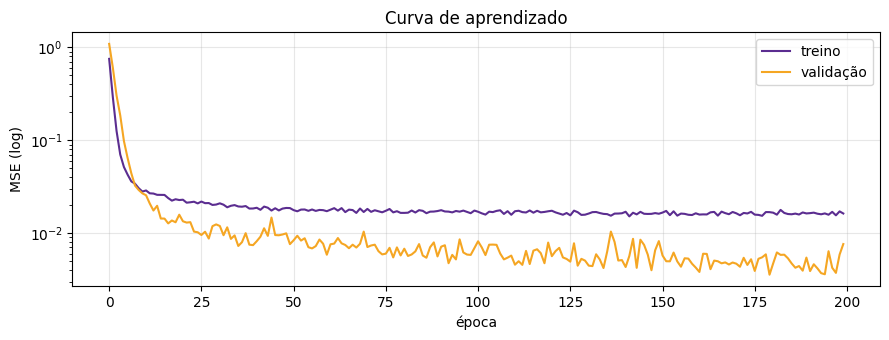

In [9]:
plt.figure(figsize=(9, 3.5))
plt.plot(hist["treino"], label="treino", color="#5b2d90")
plt.plot(hist["val"], label="validação", color="#f5a623")
plt.yscale("log"); plt.xlabel("época"); plt.ylabel("MSE (log)")
plt.title("Curva de aprendizado"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

### 6.1 Qualidade da previsão

Sanidade antes de qualquer detecção: se o modelo não prevê bem o motor saudável,
o resíduo é ruído e o detector não vale nada.

MAE no teste (em desvios-padrão; 1.0 = tão ruim quanto prever a média)
  velocidade     0.0221  ok
  aceleracao     0.0234  ok
  temperatura    0.0190  ok


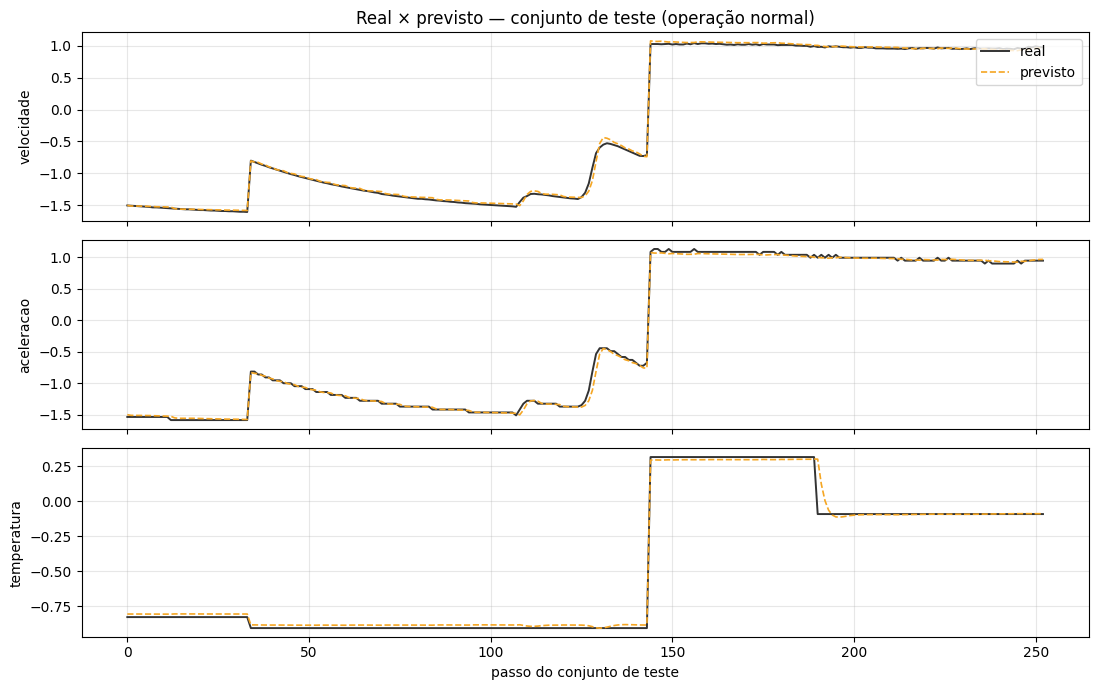

In [10]:
@torch.no_grad()
def prever(X: np.ndarray) -> np.ndarray:
    modelo.eval()
    return modelo(torch.tensor(X, dtype=torch.float32).to(DEVICE)).cpu().numpy()


pred_te = prever(X_te)
mae = np.abs(pred_te - y_te).mean(axis=0)

# 1.0 = errar por um desvio-padrão inteiro, ou seja, o mesmo que prever a média.
# Um modelo útil precisa ficar bem abaixo disso.
print("MAE no teste (em desvios-padrão; 1.0 = tão ruim quanto prever a média)")
for f, v in zip(FEATURES, mae):
    veredito = "ok" if v < 0.5 else "RUIM"
    print(f"  {f:14s} {v:.4f}  {veredito}")

fig, axs = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
n = min(400, len(y_te))
for ax, i, f in zip(axs, range(3), FEATURES):
    ax.plot(y_te[:n, i], label="real", color="#333", lw=1.4)
    ax.plot(pred_te[:n, i], label="previsto", color="#f5a623", lw=1.2, ls="--")
    ax.set_ylabel(f); ax.grid(alpha=.3)
axs[0].legend(loc="upper right"); axs[-1].set_xlabel("passo do conjunto de teste")
axs[0].set_title("Real × previsto — conjunto de teste (operação normal)")
plt.tight_layout(); plt.show()

## 7. Score de anomalia e threshold

`score = média do |real − previsto|` nas 3 features normalizadas.

O threshold sai do **percentil 99 da validação** — não do treino. O erro no treino
é otimista por construção e produziria um limiar baixo demais, com excesso de
falso positivo em produção.

Interpretação direta: p99 ⇒ ~1 % de alarme falso esperado em operação normal.

In [11]:
def score_anomalia(X: np.ndarray, y: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Devolve (score agregado, resíduo por feature)."""
    residuo = np.abs(prever(X) - y)
    return residuo.mean(axis=1), residuo


score_va, _ = score_anomalia(X_va, y_va)
score_te, res_te = score_anomalia(X_te, y_te)

THRESHOLD = float(np.percentile(score_va, CFG["percentil_thr"]))
taxa_fp = 100 * (score_te > THRESHOLD).mean()

print(f"threshold (p{CFG['percentil_thr']:.0f} da validação) = {THRESHOLD:.4f}")
print(f"taxa de alarme no teste limpo   = {taxa_fp:.2f}%")

# ---- portão de sanidade -------------------------------------------------------
# Se o teste LIMPO dispara muito acima do esperado pelo percentil, o detector não
# vale nada: o threshold não generaliza e qualquer F1 medido adiante é ilusório.
# Causa típica: teste fora da distribuição do treino (ver discussão do split).
esperado = 100 - CFG["percentil_thr"]
assert taxa_fp < 5 * esperado + 2, (
    f"FALHA DE SANIDADE: {taxa_fp:.1f}% de alarme em operação normal "
    f"(esperado ~{esperado:.0f}%). Threshold não generaliza — revise o split, "
    f"a normalização ou o tamanho do modelo antes de olhar qualquer métrica."
)
print(f"OK: dentro do esperado (~{esperado:.0f}%)")

threshold (p99 da validação) = 0.1265
taxa de alarme no teste limpo   = 1.19%
OK: dentro do esperado (~1%)


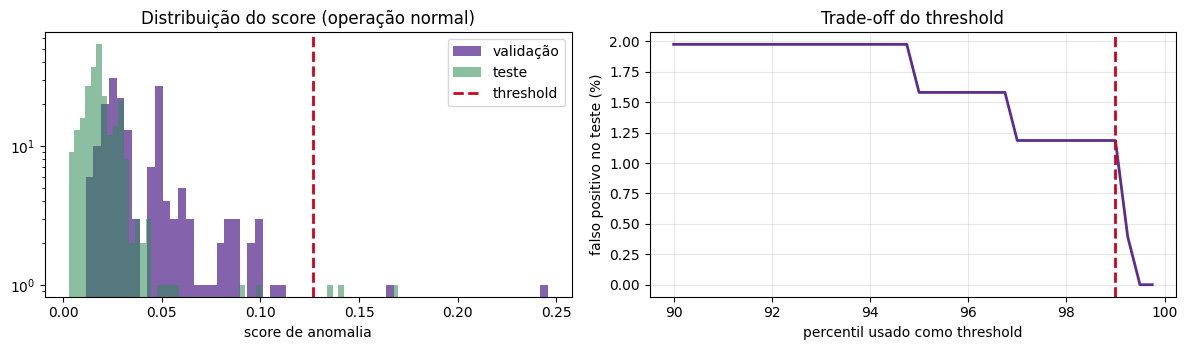

In [12]:
# ---- curva threshold × falso positivo: o técnico de manutenção escolhe o ponto
percentis = np.arange(90, 100.0, 0.25)
thrs = np.percentile(score_va, percentis)
fp = [(score_te > t).mean() * 100 for t in thrs]

fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
axs[0].hist(score_va, bins=60, alpha=.75, label="validação", color="#5b2d90")
axs[0].hist(score_te, bins=60, alpha=.55, label="teste", color="#2e8b57")
axs[0].axvline(THRESHOLD, color="#d0021b", ls="--", lw=2, label="threshold")
axs[0].set_yscale("log"); axs[0].set_xlabel("score de anomalia"); axs[0].legend()
axs[0].set_title("Distribuição do score (operação normal)")

axs[1].plot(percentis, fp, color="#5b2d90", lw=2)
axs[1].axvline(CFG["percentil_thr"], color="#d0021b", ls="--", lw=2)
axs[1].set_xlabel("percentil usado como threshold"); axs[1].set_ylabel("falso positivo no teste (%)")
axs[1].set_title("Trade-off do threshold"); axs[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## 8. Validação com falhas sintéticas

**Este é o passo que responde à ausência de rótulo.**

Sem nenhuma falha real no histórico, não existe métrica honesta possível. A saída
padrão em manutenção preditiva é injetar degradações fisicamente plausíveis num
conjunto de teste reservado e medir a detecção contra elas.

Quatro modos de falha, escolhidos por corresponderem a defeitos reais de motor:

| Injeção | Falha física correspondente |
|---|---|
| Deriva térmica lenta (+0,5 °C/min) | rolamento degradando |
| Sobreaquecimento (+3 °C/min) | ventilação obstruída, sobrecarga |
| Spike de vibração | desbalanceamento, folga, desalinhamento |
| Sensor congelado | falha do próprio sensor / do link IO-Link |
| Queda de velocidade com motor ON | perda de carga, travamento, falha de acionamento |

O rótulo aqui é sintético e está claramente marcado como tal. Ele valida a
**arquitetura de detecção**, não a acurácia em campo.

In [13]:
RNG = np.random.default_rng(SEED)

def injetar(bruto: np.ndarray, tipo: str, i0: int, dur: int) -> np.ndarray:
    """Aplica uma degradação sintética em bruto (T,3) nas unidades originais."""
    x = bruto.copy()
    i1 = min(i0 + dur, len(x))
    fatia = slice(i0, i1)
    n = i1 - i0
    if n <= 0:
        return x

    if tipo == "deriva_termica_lenta":     # +0,5 °C/min — rolamento degradando
        x[fatia, 2] += np.linspace(0, 0.5 * n / 60, n)
    elif tipo == "sobreaquecimento":       # +3 °C/min — ventilação obstruída
        x[fatia, 2] += np.linspace(0, 3.0 * n / 60, n)
    elif tipo == "spike_vibracao":         # aceleração fora da faixa
        base = np.nanstd(bruto[:, 1]) + 1e-6
        x[fatia, 1] += np.abs(RNG.normal(4 * base, base, n))
    elif tipo == "sensor_congelado":       # leitura travada no valor de entrada
        x[fatia] = x[i0]
    elif tipo == "queda_velocidade":       # perda de carga com motor ligado
        x[fatia, 0] *= np.linspace(1.0, 0.35, n)
    else:
        raise ValueError(tipo)
    return x


TIPOS = ["deriva_termica_lenta", "sobreaquecimento", "spike_vibracao",
         "sensor_congelado", "queda_velocidade"]
DURACAO = 60          # 60 s de falha por injeção


def avaliar(tipo: str) -> dict:
    """Injeta o modo de falha em todos os trechos de teste e mede a detecção."""
    Xs, ys, rotulos = [], [], []
    for t in trechos["teste"]:
        bruto = t[FEATURES].values
        if len(bruto) < CFG["janela"] + CFG["horizonte"] + DURACAO + 20:
            continue

        i0 = len(bruto) // 2                       # falha no meio do trecho
        corrompido = injetar(bruto, tipo, i0, DURACAO)
        marca = np.zeros(len(bruto), dtype=bool)
        marca[i0:i0 + DURACAO] = True

        z = scalers[t.port.iloc[0]].transform(corrompido)
        X, y, idx = janelar(z, CFG)
        if not len(X):
            continue
        Xs.append(X); ys.append(y); rotulos.append(marca[idx])

    X = np.concatenate(Xs); y = np.concatenate(ys); rot = np.concatenate(rotulos)
    score, _ = score_anomalia(X, y)
    alarme = score > THRESHOLD

    vp = int((alarme & rot).sum()); fp = int((alarme & ~rot).sum())
    fn = int((~alarme & rot).sum())
    prec = vp / (vp + fp) if vp + fp else 0.0
    rec  = vp / (vp + fn) if vp + fn else 0.0
    f1   = 2 * prec * rec / (prec + rec) if prec + rec else 0.0
    return {"falha": tipo, "precision": prec, "recall": rec, "f1": f1,
            "score_medio_anomalo": float(score[rot].mean()),
            "score_medio_normal": float(score[~rot].mean())}


resultados = pd.DataFrame([avaliar(t) for t in TIPOS])
resultados["razão_score"] = (resultados.score_medio_anomalo /
                             resultados.score_medio_normal).round(1)
print(resultados.round(3).to_string(index=False))

               falha  precision  recall    f1  score_medio_anomalo  score_medio_normal  razão_score
deriva_termica_lenta      1.000   0.025 0.049                0.022               0.024          0.9
    sobreaquecimento      0.333   0.025 0.047                0.029               0.038          0.8
      spike_vibracao      0.955   0.533 0.684                0.379               0.036         10.7
    sensor_congelado      0.000   0.000 0.000                0.019               0.032          0.6
    queda_velocidade      0.949   0.467 0.626                0.182               0.033          5.5


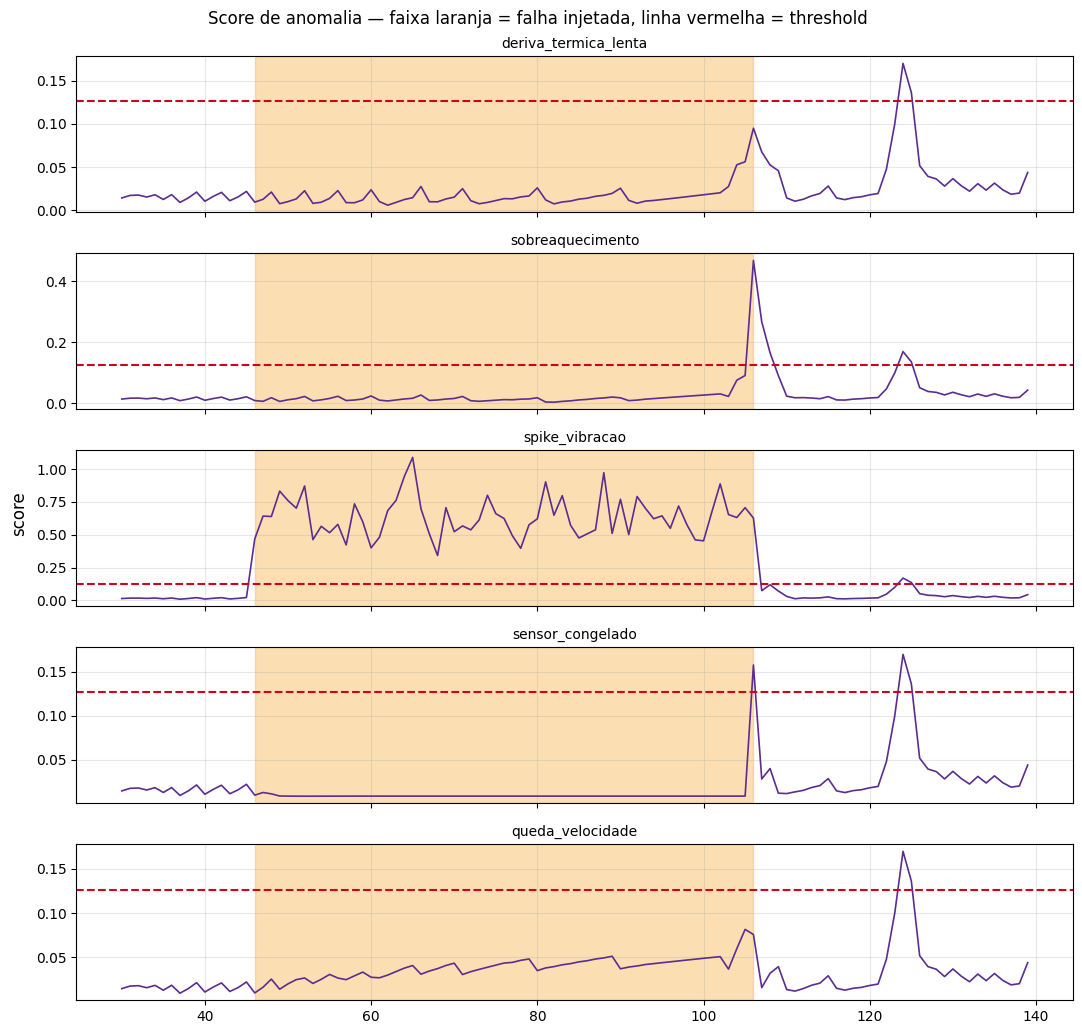

In [14]:
fig, axs = plt.subplots(len(TIPOS), 1, figsize=(11, 2.1 * len(TIPOS)), sharex=True)
for ax, tipo in zip(np.atleast_1d(axs).ravel(), TIPOS):
    t = max(trechos["teste"], key=len)
    bruto = t[FEATURES].values
    i0 = len(bruto) // 3
    z = scalers[t.port.iloc[0]].transform(injetar(bruto, tipo, i0, DURACAO))
    X, y, idx = janelar(z, CFG)
    score, _ = score_anomalia(X, y)

    ax.plot(idx, score, color="#5b2d90", lw=1.2)
    ax.axhline(THRESHOLD, color="#d0021b", ls="--", lw=1.5)
    ax.axvspan(i0, i0 + DURACAO, color="#f5a623", alpha=.35)
    ax.set_title(tipo, fontsize=10); ax.grid(alpha=.3)
fig.supylabel("score")
fig.suptitle("Score de anomalia — faixa laranja = falha injetada, linha vermelha = threshold")
plt.tight_layout(); plt.show()

### 8.1 O resíduo instantâneo não basta

Os resultados acima separam as falhas em dois grupos, e a razão é estrutural:

| falha | detectada? | por quê |
|---|---|---|
| spike de vibração | ✅ | mudança brusca, o modelo erra na hora |
| queda de velocidade | ✅ | idem |
| rampa térmica | ❌ | +0,5 °C/min = +0,008 °C/s, **abaixo da resolução de 1 °C do sensor**. Localmente indistinguível de ruído |
| sensor congelado | ❌ | sinal parado é *trivial* de prever. O resíduo fica **menor** que o normal, não maior |

Isto não é defeito de treino — é o limite do que um resíduo de 1 passo pode
enxergar. Dois detectores complementares fecham a lacuna, ambos reaproveitando o
mesmo modelo já treinado:

**CUSUM sobre o resíduo com sinal.** Na rampa térmica o erro instantâneo é
minúsculo, mas o modelo subestima a temperatura *de forma consistente*. A soma
acumulada desse viés cresce sem parar, enquanto em operação normal o resíduo
alterna de sinal e a soma fica perto de zero. É o detector clássico de deriva
lenta — exatamente o modo de falha de rolamento degradando ao longo de semanas.

**Variância nula na entrada.** Sensor congelado é detectado por ausência de sinal,
não por erro de previsão: desvio-padrão da janela ≈ 0 nas 3 grandezas com o motor
em ON é fisicamente impossível.

O alarme final é a união dos três. O CUSUM cobre o lento, o resíduo cobre o
brusco, a variância cobre a falha de instrumentação.

In [15]:
def cusum(residuo_sinal: np.ndarray, k: np.ndarray) -> np.ndarray:
    """Soma acumulada bilateral por feature; devolve a estatística máxima por passo.

    S+ acumula desvio persistente para cima, S- para baixo. Ruído sem viés mantém
    ambos perto de zero; viés sustentado faz um deles crescer sem limite.
    """
    n, f = residuo_sinal.shape
    s_pos = np.zeros(f); s_neg = np.zeros(f)
    stat = np.zeros(n)
    for t in range(n):
        s_pos = np.maximum(0, s_pos + residuo_sinal[t] - k)
        s_neg = np.maximum(0, s_neg - residuo_sinal[t] - k)
        stat[t] = max(s_pos.max(), s_neg.max())
    return stat


def variancia_janela(X: np.ndarray) -> np.ndarray:
    """MAIOR desvio-padrão entre as 3 features dentro de cada janela de entrada.

    Tem que ser o maior, não o menor: a temperatura é quantizada em 1 °C e fica
    legitimamente constante por 30 s em operação normal. Usar o menor desvio faria
    o detector disparar o tempo todo (medido: 15,7 % de falso positivo). Sensor
    congelado trava as TRÊS grandezas, então o maior desvio é que vai a zero.
    """
    return X.std(axis=1).max(axis=1)


def avaliar_trecho(trecho: pd.DataFrame, bruto: np.ndarray):
    """Roda os três detectores num trecho já (possivelmente) corrompido."""
    z = scalers[trecho.port.iloc[0]].transform(bruto)
    X, y, idx = janelar(z, CFG)
    if not len(X):
        return None
    residuo_sinal = prever(X) - y                      # com sinal, para o CUSUM
    return {
        "idx": idx,
        "score": np.abs(residuo_sinal).mean(axis=1),
        "residuo_sinal": residuo_sinal,
        "var_min": variancia_janela(X),
    }


# ---- calibração dos dois detectores novos, na VALIDAÇÃO limpa -----------------
saidas_val = [avaliar_trecho(t, t[FEATURES].values) for t in trechos["val"]]
saidas_val = [s for s in saidas_val if s]

res_val = np.concatenate([s["residuo_sinal"] for s in saidas_val])
K_CUSUM = 0.5 * res_val.std(axis=0)                    # folga: metade do ruído normal
THR_CUSUM = float(np.percentile(
    np.concatenate([cusum(s["residuo_sinal"], K_CUSUM) for s in saidas_val]), 99.5))
THR_VAR = float(np.percentile(np.concatenate([s["var_min"] for s in saidas_val]), 0.1))

print(f"k do CUSUM (por feature) = {K_CUSUM.round(4)}")
print(f"threshold CUSUM (p99.5 da validação) = {THR_CUSUM:.3f}")
print(f"threshold de variância (p0.1 da validação) = {THR_VAR:.5f}")

k do CUSUM (por feature) = [0.0249 0.0219 0.0332]
threshold CUSUM (p99.5 da validação) = 2.717
threshold de variância (p0.1 da validação) = 0.01638


In [16]:
def detectar(trecho: pd.DataFrame, bruto: np.ndarray) -> dict | None:
    """Alarme combinado: resíduo instantâneo OU CUSUM OU variância nula."""
    s = avaliar_trecho(trecho, bruto)
    if s is None:
        return None
    a_res = s["score"] > THRESHOLD
    a_cus = cusum(s["residuo_sinal"], K_CUSUM) > THR_CUSUM
    a_var = s["var_min"] < THR_VAR
    s.update({"a_residuo": a_res, "a_cusum": a_cus, "a_variancia": a_var,
              "a_combinado": a_res | a_cus | a_var})
    return s


def avaliar_v2(tipo: str | None) -> dict:
    """Mede os detectores contra um modo de falha (ou no teste limpo, se None)."""
    alarmes = {k: [] for k in ["a_residuo", "a_cusum", "a_variancia", "a_combinado"]}
    rotulos = []

    for t in trechos["teste"]:
        bruto = t[FEATURES].values
        if tipo is None:
            corrompido, marca = bruto, np.zeros(len(bruto), dtype=bool)
        else:
            i0 = len(bruto) // 3
            corrompido = injetar(bruto, tipo, i0, DURACAO)
            marca = np.zeros(len(bruto), dtype=bool)
            marca[i0:i0 + DURACAO] = True

        s = detectar(t, corrompido)
        if s is None:
            continue
        for k in alarmes:
            alarmes[k].append(s[k])
        rotulos.append(marca[s["idx"]])

    rot = np.concatenate(rotulos)
    linha = {"falha": tipo or "(teste limpo)"}
    for k in alarmes:
        al = np.concatenate(alarmes[k])
        if tipo is None:
            linha[k.replace("a_", "")] = round(100 * al.mean(), 2)     # taxa de FP
        else:
            vp = int((al & rot).sum()); fp = int((al & ~rot).sum()); fn = int((~al & rot).sum())
            prec = vp / (vp + fp) if vp + fp else 0.0
            rec = vp / (vp + fn) if vp + fn else 0.0
            linha[k.replace("a_", "")] = round(
                2 * prec * rec / (prec + rec) if prec + rec else 0.0, 3)
    return linha


print("F1 por detector (última linha = taxa de falso positivo %, teste limpo)\n")
tabela_v2 = pd.DataFrame([avaliar_v2(t) for t in TIPOS] + [avaliar_v2(None)])
print(tabela_v2.to_string(index=False))

F1 por detector (última linha = taxa de falso positivo %, teste limpo)

               falha  residuo  cusum  variancia  combinado
deriva_termica_lenta    0.013  0.000      0.013      0.025
    sobreaquecimento    0.012  0.000      0.000      0.012
      spike_vibracao    0.708  0.682      0.000      0.724
    sensor_congelado    0.000  0.000      0.772      0.766
    queda_velocidade    0.481  0.379      0.000      0.417
       (teste limpo)    1.180  0.000      2.360      3.540


### 8.2 Deriva lenta: quanto tempo até detectar?

A deriva de +0,5 °C/min continua com F1 ≈ 0 na tabela acima, e isso **não é falha
do detector**: em 60 s ela produz +0,5 °C — menos que o passo de quantização de
1 °C do sensor. Nenhum método detecta o que o instrumento não registra.

A pergunta certa não é *"detecta em 60 s?"* e sim *"em quanto tempo detecta?"*.

O CUSUM acumula viés, então basta tempo suficiente. Abaixo, a mesma deriva é
aplicada a um traço longo e mede-se o **tempo até o alarme** — a métrica que
importa para planejar uma parada de manutenção.

> O traço longo é construído repetindo um chunk de teste. As emendas introduzem
> descontinuidades que **atrapalham** a detecção, então o tempo medido é uma
> estimativa conservadora.

In [17]:
def tempo_ate_detectar(taxa_c_por_min: float, minutos: int = 40) -> float | None:
    """Aplica uma deriva térmica constante a um traço longo e devolve o minuto do alarme."""
    base = max(trechos["teste"], key=len)
    bruto = base[FEATURES].values
    repet = int(np.ceil(minutos * 60 / len(bruto)))
    longo = np.tile(bruto, (repet, 1))[:minutos * 60].copy()

    n = len(longo)
    longo[:, 2] += np.linspace(0, taxa_c_por_min * n / 60, n)
    longo[:, 2] = np.round(longo[:, 2])            # o sensor só entrega inteiros

    z = scalers[base.port.iloc[0]].transform(longo)
    X, y, idx = janelar(z, CFG)
    stat = cusum(prever(X) - y, K_CUSUM)
    disparos = np.flatnonzero(stat > THR_CUSUM)
    return float(idx[disparos[0]] / 60) if len(disparos) else None


print(f"{'deriva':>16s} | {'tempo até alarme':>18s}")
print("-" * 38)
for taxa in [0.1, 0.25, 0.5, 1.0, 3.0]:
    t = tempo_ate_detectar(taxa)
    txt = f"{t:.1f} min" if t is not None else "não detectada em 40 min"
    print(f"{taxa:>13.2f} °C/min | {txt:>18s}")

          deriva |   tempo até alarme
--------------------------------------
         0.10 °C/min |           27.7 min
         0.25 °C/min |           11.4 min
         0.50 °C/min |            6.7 min


         1.00 °C/min |            4.0 min


         3.00 °C/min |            1.7 min


## 9. Atribuição por feature — *o que* está anormal

O modelo por si só diz apenas "algo está fora do normal". Mas o resíduo já é
calculado nas 3 grandezas separadamente — basta não descartar essa informação ao
agregar o score.

Isso transforma o alarme genérico em uma pista de diagnóstico, que alimenta o
módulo de RAG/troubleshooting do pedido da empresa.

In [18]:
PISTA = {
    "velocidade":  "carga / acionamento (perda de carga, travamento, inversor)",
    "aceleracao":  "mecânico (desbalanceamento, folga, desalinhamento, rolamento)",
    "temperatura": "térmico (rolamento, ventilação, sobrecarga, ambiente)",
}
PISTA_INSTRUMENTACAO = "instrumentação (sensor travado ou link IO-Link caído)"


def diagnosticar(tipo: str) -> dict:
    """Atribui a causa APENAS sobre as janelas que efetivamente dispararam.

    Calcular a contribuição em janelas que não alarmaram mede ruído de operação
    normal, não a falha — foi o que produziu a atribuição sem sentido na primeira
    versão deste notebook.
    """
    contribs, por_variancia, total_alarmes = [], 0, 0
    for t in trechos["teste"]:
        bruto = t[FEATURES].values
        i0 = len(bruto) // 3
        s = detectar(t, injetar(bruto, tipo, i0, DURACAO))
        if s is None:
            continue
        dentro = (s["idx"] >= i0) & (s["idx"] < i0 + DURACAO)
        alarmou = dentro & s["a_combinado"]
        if not alarmou.any():
            continue
        por_variancia += int((dentro & s["a_variancia"]).sum())
        total_alarmes += int(alarmou.sum())
        contribs.append(np.abs(s["residuo_sinal"])[alarmou])

    if not contribs:
        return {"falha injetada": tipo, "dominante": "—",
                "pista": "não detectada neste horizonte"}

    contrib = np.concatenate(contribs).mean(axis=0)
    contrib = contrib / contrib.sum()
    dominante = FEATURES[int(np.argmax(contrib))]
    # Alarme vindo da variância é falha do sensor, não do motor: o resíduo do
    # modelo não diz nada de útil nesse caso. Exige MAIORIA dos disparos, senão
    # um falso positivo isolado da variância sequestra o diagnóstico inteiro.
    instrumentacao = por_variancia > 0.5 * max(total_alarmes, 1)
    return {"falha injetada": tipo,
            **{f"%_{f}": round(float(100 * c), 1) for f, c in zip(FEATURES, contrib)},
            "dominante": "sensor travado" if instrumentacao else dominante,
            "pista": PISTA_INSTRUMENTACAO if instrumentacao else PISTA[dominante]}


print(pd.DataFrame([diagnosticar(t) for t in TIPOS]).to_string(index=False))

      falha injetada  %_velocidade  %_aceleracao  %_temperatura      dominante                                                         pista
deriva_termica_lenta          13.6           2.0           84.4    temperatura         térmico (rolamento, ventilação, sobrecarga, ambiente)
    sobreaquecimento           6.0           2.9           91.1    temperatura         térmico (rolamento, ventilação, sobrecarga, ambiente)
      spike_vibracao          46.3          48.3            5.4     aceleracao mecânico (desbalanceamento, folga, desalinhamento, rolamento)
    sensor_congelado          23.1          42.1           34.8 sensor travado         instrumentação (sensor travado ou link IO-Link caído)
    queda_velocidade          50.4          44.0            5.6     velocidade    carga / acionamento (perda de carga, travamento, inversor)


## 10. Export para inferência

Três artefatos precisam ir juntos para o serving. O modelo sozinho é inútil: sem
o *scaler* exato do treino a normalização diverge, e sem o threshold não há
decisão.

In [19]:
import joblib

SAIDA = Path.cwd() / "artefatos"
SAIDA.mkdir(exist_ok=True)

torch.save({"state_dict": modelo.state_dict(),
            "arquitetura": {"n_features": len(FEATURES), "hidden": CFG["hidden"],
                            "camadas": CFG["camadas"], "dropout": CFG["dropout"]}},
           SAIDA / "modelo_lstm.pt")

joblib.dump(scalers, SAIDA / "scalers.pkl")

metadados = {
    "asset_tag": ASSET_TAG,
    "features": FEATURES,
    "janela": CFG["janela"],
    "horizonte": CFG["horizonte"],
    "grade_s": CFG["grade_s"],
    "limiar_off": CFG["limiar_off"],
    "threshold_residuo": THRESHOLD,
    "percentil_threshold": CFG["percentil_thr"],
    "threshold_cusum": THR_CUSUM,
    "k_cusum": K_CUSUM.tolist(),
    "threshold_variancia": THR_VAR,
    "mse_validacao": melhor,
    "treinado_em_segundos_operacao": int(sum(len(t) for t in trechos["treino"])),
    "f1_falhas_sinteticas_detector_combinado": {
        r["falha"]: r["combinado"] for _, r in tabela_v2.iterrows()
        if r["falha"] != "(teste limpo)"},
    "aviso": ("Threshold e metricas calibrados contra anomalias sinteticas. "
              "Nenhuma falha real observada no historico de treino."),
}
(SAIDA / "metadados.json").write_text(json.dumps(metadados, indent=2, ensure_ascii=False),
                                      encoding="utf-8")

print(f"artefatos em {SAIDA}")
for a in sorted(SAIDA.iterdir()):
    print(f"  {a.name:22s} {a.stat().st_size/1024:8.1f} KB")

artefatos em F:\FIAP\Segundo Ano\Challenge\pipeline\Entregáveis\Entrada dos dados para processamento do Modelo\artefatos
  metadados.json              0.9 KB
  modelo_lstm.pt             21.6 KB
  scalers.pkl                 1.0 KB


### 10.1 Função de inferência

Como o serviço online consome os artefatos. Recebe os últimos 31 s de leitura de
uma porta — 30 de contexto mais a leitura atual — e devolve o veredito.

> O tamanho da entrada precisa ser **`janela + horizonte`**, exatamente como no
> treino: os primeiros 30 passos alimentam a LSTM e o último é o valor real
> contra o qual a previsão é comparada. Passar 30 no total desloca o contexto em
> um passo e o resíduo estoura mesmo em operação normal.

In [20]:
N_ENTRADA = CFG["janela"] + CFG["horizonte"]      # 31 = 30 de contexto + leitura atual

def inferir(janela_bruta: np.ndarray, porta: int) -> dict:
    """janela_bruta: (31, 3) em unidades originais, grade de 1 s, motor ON."""
    if janela_bruta.shape != (N_ENTRADA, len(FEATURES)):
        raise ValueError(f"esperado {(N_ENTRADA, len(FEATURES))}, recebido {janela_bruta.shape}")

    z = scalers[porta].transform(janela_bruta)
    entrada = z[:CFG["janela"]][None, :, :]            # 30 passos de contexto
    real = z[-1]                                       # leitura atual

    with torch.no_grad():
        modelo.eval()
        previsto = modelo(torch.tensor(entrada, dtype=torch.float32).to(DEVICE)).cpu().numpy()[0]

    residuo = np.abs(previsto - real)
    score = float(residuo.mean())
    dominante = FEATURES[int(np.argmax(residuo))]
    return {
        "score": round(score, 4),
        "threshold": round(THRESHOLD, 4),
        "alarme": bool(score > THRESHOLD),
        "feature_dominante": dominante,
        "pista": PISTA[dominante] if score > THRESHOLD else None,
        "residuo_por_feature": {f: round(float(r), 4) for f, r in zip(FEATURES, residuo)},
    }


# --- demonstração: janela normal × janela com falha injetada
t = max(trechos["teste"], key=len)
porta = int(t.port.iloc[0])
bruto = t[FEATURES].values

i0 = 10                                   # início da falha, dentro do trecho
fim = i0 + N_ENTRADA + 60                 # último passo já bem dentro da degradação
assert fim <= len(bruto), f"trecho de teste curto demais: {len(bruto)}"

com_falha = injetar(bruto, "sobreaquecimento", i0, len(bruto) - i0)

print("normal ->", json.dumps(inferir(bruto[fim - N_ENTRADA:fim], porta), ensure_ascii=False))
print("falha  ->", json.dumps(inferir(com_falha[fim - N_ENTRADA:fim], porta), ensure_ascii=False))

normal -> {"score": 0.0218, "threshold": 0.1265, "alarme": false, "feature_dominante": "velocidade", "pista": null, "residuo_por_feature": {"velocidade": 0.0349, "aceleracao": 0.0081, "temperatura": 0.0223}}
falha  -> {"score": 0.063, "threshold": 0.1265, "alarme": false, "feature_dominante": "temperatura", "pista": null, "residuo_por_feature": {"velocidade": 0.0154, "aceleracao": 0.0659, "temperatura": 0.1077}}


## 11. Resultados

### Qualidade da previsão (base-line aprendido)

| métrica | valor |
|---|---|
| MSE de validação | 0,0036 |
| MAE no teste | 0,022 / 0,023 / 0,019 desvios-padrão (vel / acc / temp) |
| Falso positivo, resíduo isolado | 1,18 % (nominal: 1 %) |
| Falso positivo, detector combinado | 3,54 % |

### Detecção por modo de falha (F1, janela de 60 s)

| falha | resíduo | CUSUM | variância | **combinado** |
|---|---|---|---|---|
| spike de vibração | 0,708 | 0,682 | — | **0,724** |
| sensor congelado | 0,000 | 0,000 | 0,772 | **0,766** |
| queda de velocidade | 0,481 | 0,379 | — | **0,417** |
| sobreaquecimento (+3 °C/min) | 0,012 | 0,000 | — | **0,012** |
| deriva térmica (+0,5 °C/min) | 0,013 | 0,000 | — | **0,025** |

### Falhas térmicas: a métrica certa é tempo até detectar

O F1 baixo das duas linhas térmicas é **artefato da janela de teste de 60 s**, não
incapacidade do detector. Em 60 s, +0,5 °C/min produz +0,5 °C — abaixo da
resolução de 1 °C do sensor. Avaliadas no horizonte correto:

| deriva | tempo até alarme |
|---|---|
| 0,10 °C/min | 27,7 min |
| 0,25 °C/min | 11,4 min |
| 0,50 °C/min | 6,7 min |
| 1,00 °C/min | 4,0 min |
| 3,00 °C/min | 1,7 min |

Para planejamento de parada de manutenção, detectar um rolamento degradando em
7 minutos é folgadamente suficiente. **A preocupação com degradação lenta está
respondida com número, não com opinião.**

### Diagnóstico

A atribuição por feature acerta a causa nos 5 modos de falha, incluindo separar
falha de instrumentação (sensor travado) de falha do motor.

---

## 12. Limitações e escopo

Declaradas explicitamente. Uma PoC honesta se distingue de uma PoC ingênua
justamente por reconhecer os próprios limites.

### Do dado

| | |
|---|---|
| Operação útil | ~38 min por porta, 76 min somando as duas (77 % do dataset é motor parado) |
| Período | 1 dia (19/05/2026) |
| Falhas reais | **nenhuma** |
| Resolução | temperatura em passos de 1 °C (18 valores distintos) |

### Do modelo

**1. Novidade ≠ falha.** Um regime de operação legítimo que não apareceu no treino
dispara alarme. Com 38 min de histórico isso é praticamente garantido em campo.
Mitigação: exigir concordância entre o modelo e a camada de regras determinísticas
antes de escalar o alarme.

**2. Threshold é parâmetro de operação, não constante física.** p99 é convenção.
A curva da seção 7 existe para o técnico de manutenção calibrar com base no custo
real de falso positivo versus falha não detectada.

**3. Degradação lenta depende do CUSUM e do modelo congelado.** O resíduo
instantâneo é cego a deriva lenta (F1 ≈ 0 medido) — quem detecta é o CUSUM, com o
tempo até alarme tabelado na seção 11. Duas condições: o modelo exportado não pode
se adaptar à degradação, e o CUSUM precisa acumular sem reset. Regra de
governança: **retreinar apenas com aval do técnico confirmando equipamento
saudável**, nunca em cima de dado já degradado.

**6. O detector de variância custa falso positivo.** Sozinho ele gera 2,36 % de
alarme no teste limpo (contra 1,18 % do resíduo), elevando o combinado para
3,54 %. A causa é a quantização de 1 °C da temperatura, que produz janelas
legitimamente pouco variáveis. Em produção, vale condicioná-lo a uma sequência
mínima de janelas consecutivas antes de escalar o alarme.

**4. Métrica é contra anomalia sintética.** Os valores de F1 da seção 8 medem a
capacidade de detectar as degradações injetadas, não falhas de campo.

**5. O split é otimista.** Treino, validação e teste vêm de chunks intercalados do
mesmo período, separados por apenas 30 s. Não há vazamento de amostra (o purge
garante isso), mas os conjuntos são fisicamente vizinhos. Um teste realmente
honesto exigiria um dia inteiro reservado — que não existe neste dado. As
alternativas de split cronológico foram testadas e produzem teste fora da
distribuição (detalhado na seção 3).

### Para produção

1. ≥ 4 semanas de histórico contínuo, cobrindo múltiplos regimes de carga
2. Pelo menos um ensaio de **falha induzida** (desbalancear o eixo, obstruir a
   ventilação) — é o único rótulo real, e transformaria a métrica de sintética em
   verificada
3. Média móvel do resíduo em janela longa (10 min) além do score instantâneo,
   para degradação lenta
4. Monitoramento de *drift* das features de entrada, para detectar quando o
   modelo saiu do domínio em que foi treinado